# Employee Attrition Problem Definition, Exploratory Analytics, and Planning

**Academic Project**: Employee Attrition Problem Definition & Planning  
**Role**: Senior HR Data Analyst & Lead People Analytics Specialist  
**Dataset**: IBM HR Analytics Employee Attrition & Performance Benchmark  
**Environment**: Python 3.11, Pandas, NumPy, Matplotlib, Seaborn  

---

## Executive Summary & Notebook Scope
This notebook establishes the formal diagnostic and exploratory data analysis (EDA) baseline for organizational employee attrition.
The primary objectives are:
1. **Data Ingestion & Integrity Validation**: Inspect the 1,470 records and 35 columns, auditing data types, missingness, and structural anomalies.
2. **Target Variable Validation**: Analyze the `Attrition` target class distribution, quantify the ~5.2:1 class imbalance, and define the positive class (`Yes`).
3. **Exploratory Univariate & Bivariate Analytics**: Diagnose the empirical relationships between employee departure and organizational drivers (overtime workload, compensation, tenure, job roles, and satisfaction).
4. **Correlation Analysis & Methodological Rigor**: Compute linear associations across continuous features while documenting the critical distinctions between correlation and causation.
5. **Ethical & Governance Context**: Audit protected demographic attributes (`Age`, `Gender`, `MaritalStatus`) to establish strict algorithmic fairness and non-discrimination baselines before Phase 2 predictive modeling.

## 1. Environment Setup & Library Imports
We configure standard data manipulation, statistical, and plotting libraries. All warnings are managed cleanly to ensure academic reproducibility.

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configure plotting parameters
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
sns.set_theme(style="whitegrid", font="sans-serif")
palette = ["#2b5c8f", "#d95f02"]  # Primary Corporate Blue, Highlight Orange

# Ensure output directories exist
os.makedirs('../outputs/figures', exist_ok=True)
os.makedirs('../outputs/tables', exist_ok=True)

print("Python version:", sys.version.split()[0])
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)
print("Seaborn version:", sns.__version__)

Python version: 3.11.0
Pandas version: 3.0.1
NumPy version: 2.4.6
Seaborn version: 0.13.2


## 2. Data Loading & Schema Inspection
We load the validated IBM HR Analytics dataset (`WA_Fn-UseC_-HR-Employee-Attrition.csv`) from the local `data/` directory.
We inspect dataset dimensions, sample records, and column data types.

In [2]:
# Load the dataset
dataset_path = os.path.join('..', 'data', 'WA_Fn-UseC_-HR-Employee-Attrition.csv')
if not os.path.exists(dataset_path):
    dataset_path = 'data/WA_Fn-UseC_-HR-Employee-Attrition.csv'

df = pd.read_csv(dataset_path)

print(f"Dataset Dimensions: {df.shape[0]} rows (employees) x {df.shape[1]} columns (features)")
print(f"Total Cells: {df.size:,}")

Dataset Dimensions: 1470 rows (employees) x 35 columns (features)
Total Cells: 51,450


In [3]:
# Display first 5 records
df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [4]:
# Inspect Column Names, Non-Null Counts, and Data Types
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   Age                       1470 non-null   int64
 1   Attrition                 1470 non-null   str  
 2   BusinessTravel            1470 non-null   str  
 3   DailyRate                 1470 non-null   int64
 4   Department                1470 non-null   str  
 5   DistanceFromHome          1470 non-null   int64
 6   Education                 1470 non-null   int64
 7   EducationField            1470 non-null   str  
 8   EmployeeCount             1470 non-null   int64
 9   EmployeeNumber            1470 non-null   int64
 10  EnvironmentSatisfaction   1470 non-null   int64
 11  Gender                    1470 non-null   str  
 12  HourlyRate                1470 non-null   int64
 13  JobInvolvement            1470 non-null   int64
 14  JobLevel                  1470 non-null   int64
 15

## 3. Data Integrity & Missing-Value Audit
A critical step in professional data science is verifying data completeness.
We check for missing (null) values, duplicates, and non-informative constant columns.

In [5]:
# Audit missing values across all 35 columns
missing_counts = df.isnull().sum()
missing_pct = (missing_counts / len(df)) * 100

data_quality_df = pd.DataFrame({
    'Column': df.columns,
    'Data_Type': df.dtypes.astype(str),
    'Missing_Count': missing_counts.values,
    'Missing_Percentage': missing_pct.values,
    'Unique_Values': [df[col].nunique() for col in df.columns]
})

print(f"Total Missing Values in Entire Dataset: {df.isnull().sum().sum()}")
print(f"Duplicate Rows Count: {df.duplicated().sum()}")
data_quality_df.head(10)

Total Missing Values in Entire Dataset: 0
Duplicate Rows Count: 0


,Column,Data_Type,Missing_Count,Missing_Percentage,Unique_Values
Age,Age,int64,0,0.0,43
Attrition,Attrition,str,0,0.0,2
BusinessTravel,BusinessTravel,str,0,0.0,3
DailyRate,DailyRate,int64,0,0.0,886
Department,Department,str,0,0.0,3
DistanceFromHome,DistanceFromHome,int64,0,0.0,29
Education,Education,int64,0,0.0,5
EducationField,EducationField,str,0,0.0,6
EmployeeCount,EmployeeCount,int64,0,0.0,1
EmployeeNumber,EmployeeNumber,int64,0,0.0,1470


### 3.1 Identification of Constant Columns and Primary Identifiers
In tabular datasets, features with zero variance provide zero informational entropy and can destabilize covariance matrices or cause overfitting:
- `EmployeeCount`: Uniformly equal to `1` across all 1,470 records.
- `StandardHours`: Uniformly equal to `80` across all 1,470 records.
- `Over18`: Uniformly `'Y'` across all 1,470 records.
- `EmployeeNumber`: Unique administrative employee ID (1 to 2068). This is an arbitrary primary key and must not be used as a predictor to avoid data leakage.

In [6]:
# Verify zero-variance constants and identifier
constant_cols = [col for col in df.columns if df[col].nunique() == 1]
print("Constant / Zero-Variance Columns identified:", constant_cols)

for c in constant_cols:
    print(f" - {c}: unique value = {df[c].unique()}")

print(f"EmployeeNumber unique values count: {df['EmployeeNumber'].nunique()} (equal to row count: {df['EmployeeNumber'].nunique() == len(df)})")

Constant / Zero-Variance Columns identified: ['EmployeeCount', 'Over18', 'StandardHours']
 - EmployeeCount: unique value = [1]
 - Over18: unique value = <ArrowStringArray>
['Y']
Length: 1, dtype: str
 - StandardHours: unique value = [80]
EmployeeNumber unique values count: 1470 (equal to row count: True)


## 4. Target Variable Analysis: `Attrition`
The target variable is `Attrition`, indicating whether the employee has separated from the organization (`Yes`) or remains active (`No`).
Here we validate its distribution, calculate the exact class proportions, and evaluate class imbalance.

In [7]:
# Calculate target class frequencies
attrition_counts = df['Attrition'].value_counts()
attrition_proportions = df['Attrition'].value_counts(normalize=True) * 100

target_summary = pd.DataFrame({
    'Headcount': attrition_counts,
    'Percentage (%)': attrition_proportions.round(2)
})
print("Target Class Summary Table:")
display(target_summary)

imbalance_ratio = attrition_counts['No'] / attrition_counts['Yes']
print(f"\nClass Imbalance Ratio (Negative : Positive): {imbalance_ratio:.2f} : 1")

Target Class Summary Table:


,Headcount,Percentage (%)
Attrition,,
No,1233,83.88
Yes,237,16.12



Class Imbalance Ratio (Negative : Positive): 5.20 : 1


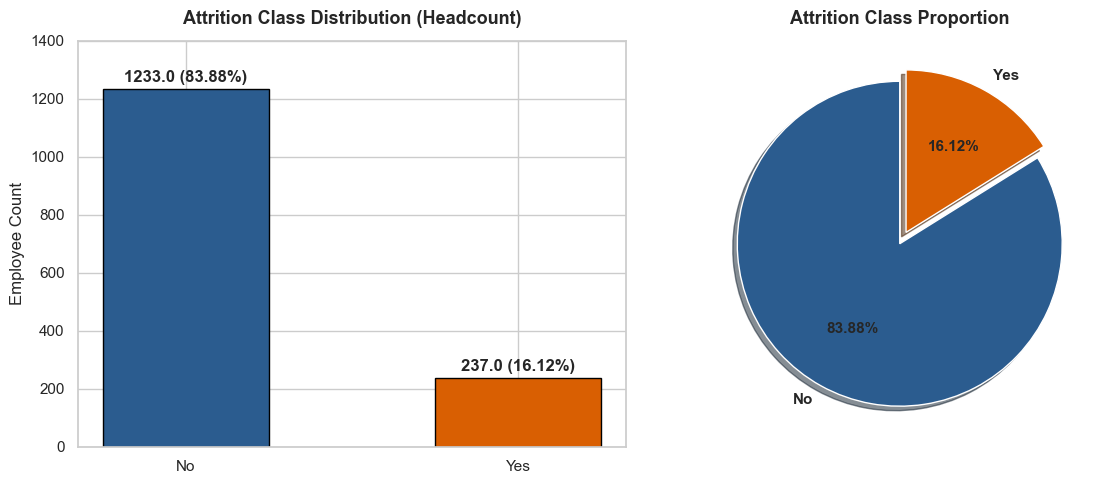

In [8]:
# Visualize Target Distribution
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Bar chart
ax1.bar(target_summary.index, target_summary['Headcount'], color=['#2b5c8f', '#d95f02'], width=0.5, edgecolor='black')
for i, (idx, row) in enumerate(target_summary.iterrows()):
    ax1.text(i, row['Headcount'] + 25, f"{row['Headcount']} ({row['Percentage (%)']}%)", ha='center', fontweight='bold')
ax1.set_title('Attrition Class Distribution (Headcount)', fontsize=13, fontweight='bold', pad=12)
ax1.set_ylabel('Employee Count')
ax1.set_ylim(0, 1400)

# Donut chart
ax2.pie(target_summary['Headcount'], labels=target_summary.index, autopct='%1.2f%%', startangle=90,
        colors=['#2b5c8f', '#d95f02'], explode=(0, 0.08), shadow=True, textprops={'fontsize': 11, 'fontweight': 'bold'})
ax2.set_title('Attrition Class Proportion', fontsize=13, fontweight='bold', pad=12)

plt.tight_layout()
plt.show()

## 5. Departmental & Job Role Diagnostics
We disaggregate attrition patterns by organizational business unit and functional job role.
We compute both:
1. **Within-Group Attrition Rate (%)**: The percentage of employees *within that specific department/role* who left.
2. **Share of Total Attrition (%)**: The proportion of *all 237 departures* accounted for by that department/role.

In [9]:
# Department-Level Breakdown
dept_summary = df.groupby('Department')['Attrition'].agg(
    Total_Employees='count',
    Departures=lambda x: (x == 'Yes').sum(),
    Retention_Count=lambda x: (x == 'No').sum(),
    Attrition_Rate=lambda x: (x == 'Yes').mean() * 100,
    Share_of_Total_Attrition=lambda x: (x == 'Yes').sum() / (df['Attrition'] == 'Yes').sum() * 100
).reset_index()

dept_summary['Attrition_Rate'] = dept_summary['Attrition_Rate'].round(2)
dept_summary['Share_of_Total_Attrition'] = dept_summary['Share_of_Total_Attrition'].round(2)

print("Department-Level Attrition Breakdown:")
display(dept_summary)

Department-Level Attrition Breakdown:


,Department,Total_Employees,Departures,Retention_Count,Attrition_Rate,Share_of_Total_Attrition
0,Human Resources,63,12,51,19.05,5.06
1,Research & Development,961,133,828,13.84,56.12
2,Sales,446,92,354,20.63,38.82


In [10]:
# Job Role Breakdown (Sorted by Attrition Rate)
role_summary = df.groupby('JobRole')['Attrition'].agg(
    Total_Employees='count',
    Departures=lambda x: (x == 'Yes').sum(),
    Attrition_Rate=lambda x: (x == 'Yes').mean() * 100,
    Share_of_Total_Attrition=lambda x: (x == 'Yes').sum() / (df['Attrition'] == 'Yes').sum() * 100
).sort_values(by='Attrition_Rate', ascending=False).reset_index()

role_summary['Attrition_Rate'] = role_summary['Attrition_Rate'].round(2)
role_summary['Share_of_Total_Attrition'] = role_summary['Share_of_Total_Attrition'].round(2)

print("Job Role Attrition Breakdown (Ranked by Flight Risk):")
display(role_summary)

Job Role Attrition Breakdown (Ranked by Flight Risk):


,JobRole,Total_Employees,Departures,Attrition_Rate,Share_of_Total_Attrition
0,Sales Representative,83,33,39.76,13.92
1,Laboratory Technician,259,62,23.94,26.16
2,Human Resources,52,12,23.08,5.06
3,Sales Executive,326,57,17.48,24.05
4,Research Scientist,292,47,16.10,19.83
5,Manufacturing Director,145,10,6.90,4.22
6,Healthcare Representative,131,9,6.87,3.80
7,Manager,102,5,4.90,2.11
8,Research Director,80,2,2.50,0.84


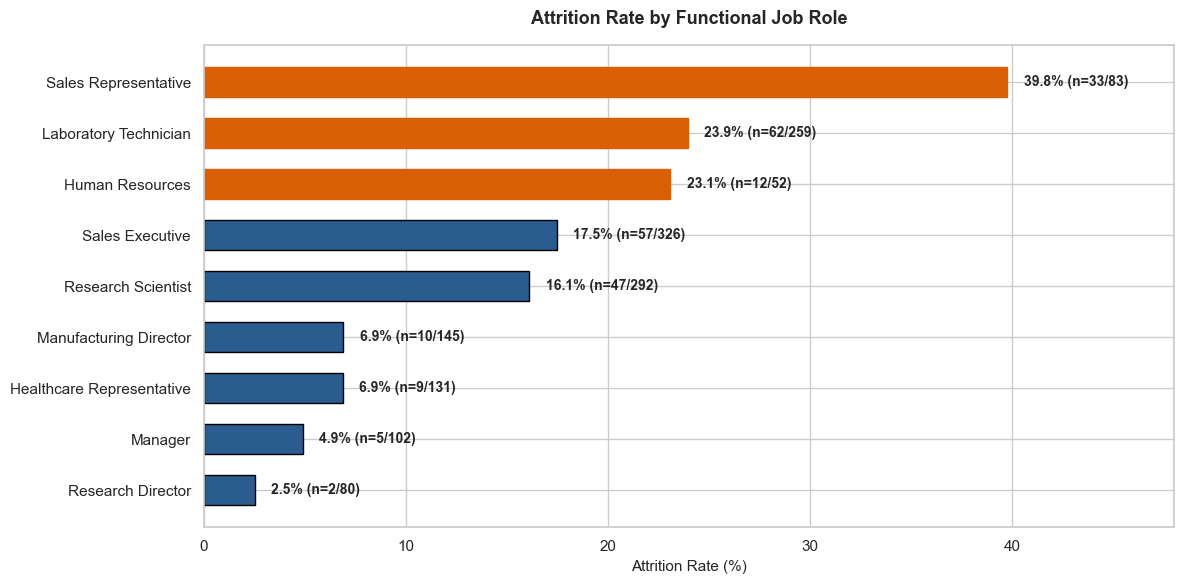

In [11]:
# Visualize Job Role Attrition Rates
fig, ax = plt.subplots(figsize=(12, 6))
bars = ax.barh(role_summary['JobRole'][::-1], role_summary['Attrition_Rate'][::-1],
               color='#2b5c8f', edgecolor='black', height=0.6)

# Highlight high risk roles (>20%)
for idx, bar in enumerate(bars):
    val = role_summary['Attrition_Rate'][::-1].iloc[idx]
    if val > 20.0:
        bar.set_color('#d95f02')
    ax.text(val + 0.8, idx, f"{val:.1f}% (n={role_summary['Departures'][::-1].iloc[idx]}/{role_summary['Total_Employees'][::-1].iloc[idx]})",
            va='center', fontweight='bold', fontsize=10)

ax.set_title('Attrition Rate by Functional Job Role', fontsize=13, fontweight='bold', pad=15)
ax.set_xlabel('Attrition Rate (%)', fontsize=11)
ax.set_xlim(0, 48)
plt.tight_layout()
plt.show()

## 6. Workload Demands: Overtime & Business Travel
We investigate the association between working hours demand (`OverTime`), business travel frequency, and flight risk.

In [12]:
# Overtime Analysis
ot_summary = df.groupby('OverTime')['Attrition'].agg(
    Total_Employees='count',
    Departures=lambda x: (x == 'Yes').sum(),
    Attrition_Rate=lambda x: (x == 'Yes').mean() * 100
).reset_index()

ot_summary['Attrition_Rate'] = ot_summary['Attrition_Rate'].round(2)
print("OverTime Attrition Analysis:")
display(ot_summary)

ot_ratio = ot_summary.loc[ot_summary['OverTime'] == 'Yes', 'Attrition_Rate'].values[0] / ot_summary.loc[ot_summary['OverTime'] == 'No', 'Attrition_Rate'].values[0]
print(f"\nRelative Risk: Employees working OverTime exhibit a {ot_ratio:.2f}x higher attrition rate than non-overtime staff.")

OverTime Attrition Analysis:


,OverTime,Total_Employees,Departures,Attrition_Rate
0,No,1054,110,10.44
1,Yes,416,127,30.53



Relative Risk: Employees working OverTime exhibit a 2.92x higher attrition rate than non-overtime staff.


In [13]:
# Business Travel Analysis
travel_summary = df.groupby('BusinessTravel')['Attrition'].agg(
    Total_Employees='count',
    Departures=lambda x: (x == 'Yes').sum(),
    Attrition_Rate=lambda x: (x == 'Yes').mean() * 100
).reset_index()

travel_summary['Attrition_Rate'] = travel_summary['Attrition_Rate'].round(2)
print("Business Travel Attrition Analysis:")
display(travel_summary)

Business Travel Attrition Analysis:


,BusinessTravel,Total_Employees,Departures,Attrition_Rate
0,Non-Travel,150,12,8.00
1,Travel_Frequently,277,69,24.91
2,Travel_Rarely,1043,156,14.96


## 7. Compensation, Experience, and Tenure Comparisons
We compare the statistical distributions of numerical continuous variables across retained and departing employees:
- `MonthlyIncome`
- `TotalWorkingYears`
- `YearsAtCompany`
- `YearsWithCurrManager`

In [14]:
# Statistical Comparison of Key Continuous Features
cont_cols = ['MonthlyIncome', 'Age', 'TotalWorkingYears', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsWithCurrManager']

comp_stats = []
for c in cont_cols:
    no_stats = df[df['Attrition'] == 'No'][c]
    yes_stats = df[df['Attrition'] == 'Yes'][c]
    comp_stats.append({
        'Feature': c,
        'Retained_Mean': round(no_stats.mean(), 2),
        'Departed_Mean': round(yes_stats.mean(), 2),
        'Retained_Median': round(no_stats.median(), 2),
        'Departed_Median': round(yes_stats.median(), 2),
        'Difference_in_Median': round(yes_stats.median() - no_stats.median(), 2)
    })

comp_df = pd.DataFrame(comp_stats)
display(comp_df)

,Feature,Retained_Mean,Departed_Mean,Retained_Median,Departed_Median,Difference_in_Median
0,MonthlyIncome,6832.74,4787.09,5204.0,3202.0,-2002.0
1,Age,37.56,33.61,36.0,32.0,-4.0
2,TotalWorkingYears,11.86,8.24,10.0,7.0,-3.0
3,YearsAtCompany,7.37,5.13,6.0,3.0,-3.0
4,YearsInCurrentRole,4.48,2.90,3.0,2.0,-1.0
5,YearsWithCurrManager,4.37,2.85,3.0,2.0,-1.0


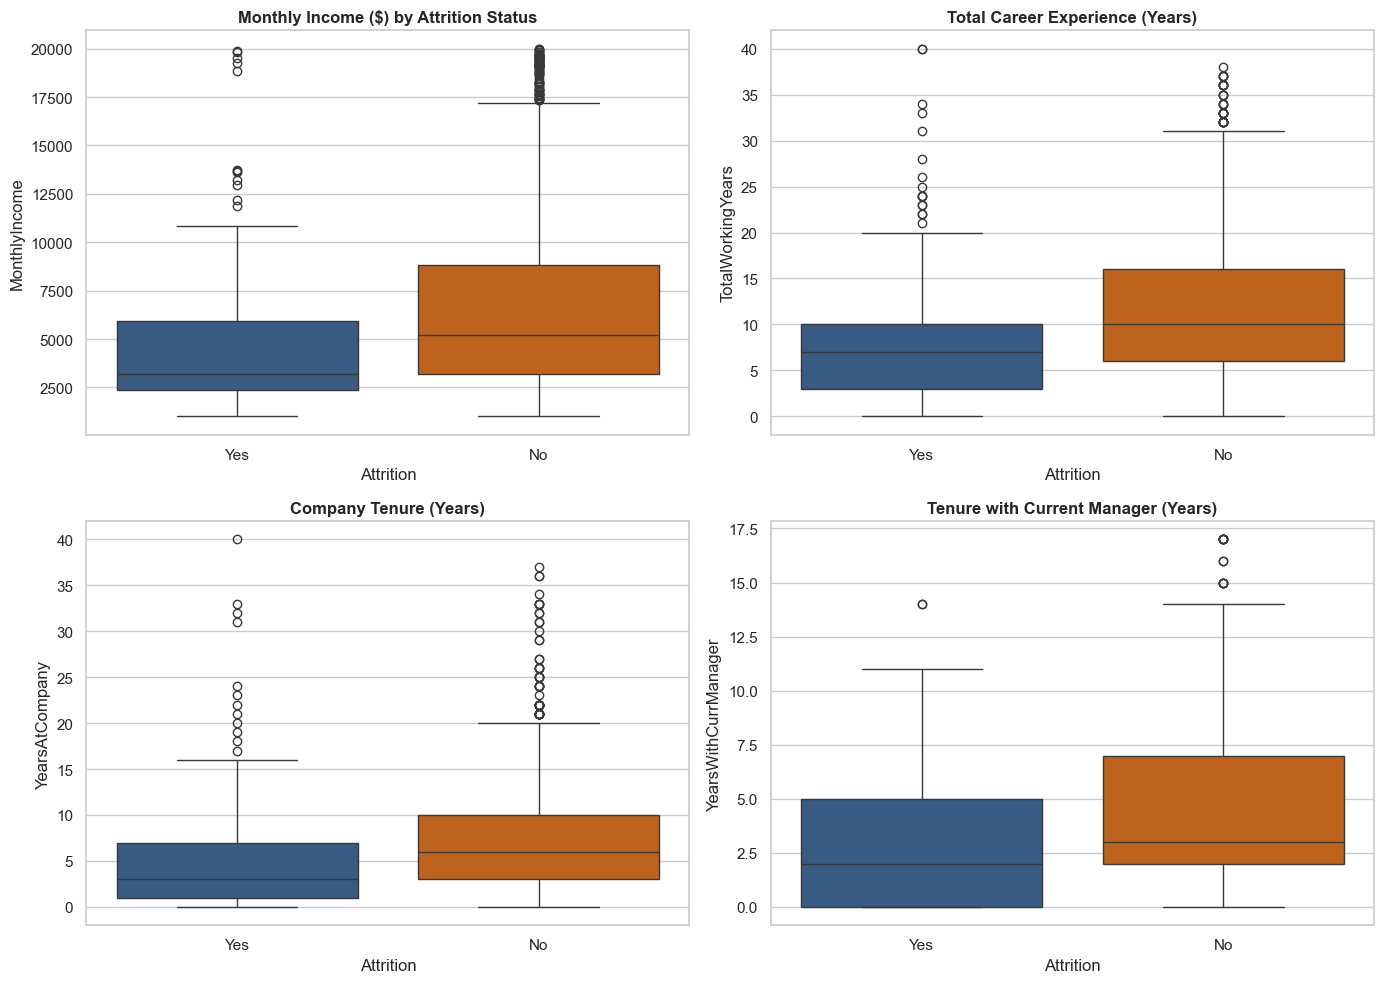

In [15]:
# Multi-panel Boxplots comparing distributions
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.boxplot(x='Attrition', y='MonthlyIncome', data=df, ax=axes[0, 0], hue='Attrition', palette=['#2b5c8f', '#d95f02'], legend=False)
axes[0, 0].set_title('Monthly Income ($) by Attrition Status', fontsize=12, fontweight='bold')

sns.boxplot(x='Attrition', y='TotalWorkingYears', data=df, ax=axes[0, 1], hue='Attrition', palette=['#2b5c8f', '#d95f02'], legend=False)
axes[0, 1].set_title('Total Career Experience (Years)', fontsize=12, fontweight='bold')

sns.boxplot(x='Attrition', y='YearsAtCompany', data=df, ax=axes[1, 0], hue='Attrition', palette=['#2b5c8f', '#d95f02'], legend=False)
axes[1, 0].set_title('Company Tenure (Years)', fontsize=12, fontweight='bold')

sns.boxplot(x='Attrition', y='YearsWithCurrManager', data=df, ax=axes[1, 1], hue='Attrition', palette=['#2b5c8f', '#d95f02'], legend=False)
axes[1, 1].set_title('Tenure with Current Manager (Years)', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

## 8. Employee Sentiment and Survey Ratings
We examine the 4-point Likert ratings:
- `JobSatisfaction` (1: Low to 4: Very High)
- `EnvironmentSatisfaction` (1: Low to 4: Very High)
- `WorkLifeBalance` (1: Bad to 4: Best)

In [16]:
# Satisfaction cross-tabulations
for sat_col in ['JobSatisfaction', 'EnvironmentSatisfaction', 'WorkLifeBalance']:
    agg = df.groupby(sat_col)['Attrition'].agg(
        Total='count',
        Departures=lambda x: (x == 'Yes').sum(),
        Attrition_Rate=lambda x: (x == 'Yes').mean() * 100
    ).reset_index()
    agg['Attrition_Rate'] = agg['Attrition_Rate'].round(2)
    print(f"\n--- {sat_col} Breakdown ---")
    display(agg)


--- JobSatisfaction Breakdown ---


,JobSatisfaction,Total,Departures,Attrition_Rate
0,1,289,66,22.84
1,2,280,46,16.43
2,3,442,73,16.52
3,4,459,52,11.33



--- EnvironmentSatisfaction Breakdown ---


,EnvironmentSatisfaction,Total,Departures,Attrition_Rate
0,1,284,72,25.35
1,2,287,43,14.98
2,3,453,62,13.69
3,4,446,60,13.45



--- WorkLifeBalance Breakdown ---


,WorkLifeBalance,Total,Departures,Attrition_Rate
0,1,80,25,31.25
1,2,344,58,16.86
2,3,893,127,14.22
3,4,153,27,17.65


## 9. Pearson Linear Correlation Analysis
We compute the Pearson linear correlation matrix for suitable continuous and discrete numerical variables.

### Methodological Notes & Ethical Caveats:
1. **Correlation Does Not Imply Causation**: A strong linear association (e.g., between `MonthlyIncome` and `TotalWorkingYears`) reflects seniority-based pay structures, not an independent causal mechanism.
2. **Exclusion of Non-Continuous Columns**: Categorical nominal variables (`Department`, `JobRole`, `EducationField`) must **never** be arbitrarily mapped to integers (e.g. Sales=1, R&D=2, HR=3) because arbitrary integers impose false geometric distances and fictitious linear trends.
3. **Ordinal Cautions**: Likert ratings are discrete ordinal scales with non-uniform psychological distances and must be interpreted cautiously.

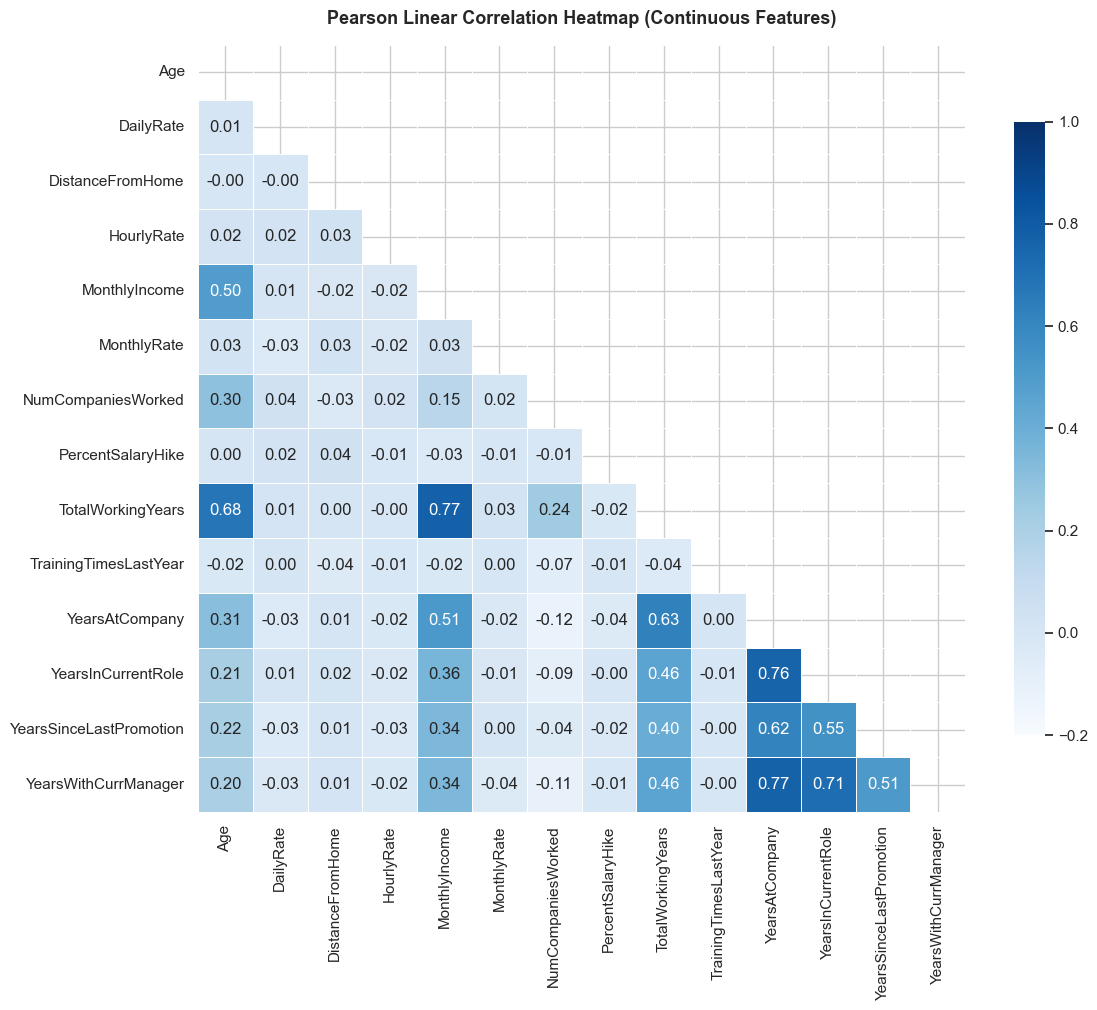

In [17]:
# Select continuous and discrete numerical variables
corr_cols = [
    'Age', 'DailyRate', 'DistanceFromHome', 'HourlyRate', 'MonthlyIncome', 'MonthlyRate',
    'NumCompaniesWorked', 'PercentSalaryHike', 'TotalWorkingYears', 'TrainingTimesLastYear',
    'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager'
]

corr_matrix = df[corr_cols].corr()

# Plot heatmap
fig, ax = plt.subplots(figsize=(12, 10))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.2f', cmap='Blues', vmin=-0.2, vmax=1.0,
            square=True, linewidths=0.5, cbar_kws={"shrink": 0.8}, ax=ax)
ax.set_title('Pearson Linear Correlation Heatmap (Continuous Features)', fontsize=13, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

## 10. Protected Demographics & Ethical Fairness Audit
To adhere to labor non-discrimination standards (Title VII of the Civil Rights Act, Age Discrimination in Employment Act), we audit attrition distributions across protected demographic attributes:
- `Gender`
- `MaritalStatus`
- `Age` cohorts

**Strict Governance Mandate**: These attributes must be evaluated to ensure company policies do not inadvertently produce disparate impact. However, individual predictions in Phase 2 must **never** be used to deny promotions, alter compensation, or execute adverse employment actions.

In [18]:
# Demographic Cross-Tabulation
print("--- Gender Attrition Profile ---")
gender_agg = df.groupby('Gender')['Attrition'].agg(
    Total='count',
    Departures=lambda x: (x == 'Yes').sum(),
    Attrition_Rate=lambda x: (x == 'Yes').mean() * 100
).reset_index()
gender_agg['Attrition_Rate'] = gender_agg['Attrition_Rate'].round(2)
display(gender_agg)

print("\n--- Marital Status Attrition Profile ---")
marital_agg = df.groupby('MaritalStatus')['Attrition'].agg(
    Total='count',
    Departures=lambda x: (x == 'Yes').sum(),
    Attrition_Rate=lambda x: (x == 'Yes').mean() * 100
).reset_index()
marital_agg['Attrition_Rate'] = marital_agg['Attrition_Rate'].round(2)
display(marital_agg)

--- Gender Attrition Profile ---


,Gender,Total,Departures,Attrition_Rate
0,Female,588,87,14.80
1,Male,882,150,17.01



--- Marital Status Attrition Profile ---


,MaritalStatus,Total,Departures,Attrition_Rate
0,Divorced,327,33,10.09
1,Married,673,84,12.48
2,Single,470,120,25.53


## 11. Empirical Findings Summary & Project Roadmap

### Key Diagnostic Findings:
1. **Target Baseline**: The dataset exhibits an overall attrition proportion of **16.12% (237 departed employees out of 1,470)**, establishing a **5.2:1 class imbalance**.
2. **Workload Risk Driver**: Personnel working **OverTime** experience an attrition rate of **30.53%**, compared to **10.44%** among non-overtime staff (nearly 3x higher relative risk).
3. **Role-Specific Vulnerability**: **Sales Representatives** experience the highest turnover rate at **39.76%**, while **Laboratory Technicians** represent the largest single departure volume (**62 departures**, representing **26.16%** of all organizational turnover).
4. **Compensation Disparity**: Departed employees had a median monthly salary of **$3,202**, compared to **$5,204** for retained personnel (a **38.5%** gap).
5. **Early-Career Hazard**: Median tenure among departed employees was **3.0 years** at the company and **2.0 years** with their current manager, indicating acute retention vulnerability during early career socialization.
6. **Data Hygiene & Completeness**: All 35 features are **100% complete** (0 missing values), with 3 zero-variance constants (`EmployeeCount`, `StandardHours`, `Over18`) and 1 primary key (`EmployeeNumber`) identified for exclusion from predictive modeling.

---

### Transition to Phase 2: Predictive Modeling Roadmap
With the business problem formally specified, feature dictionary published, business KPIs standardized, and exploratory data analysis verified, the foundation is established for **Phase 2 Predictive Modeling**:
- Data pre-processing and categorical one-hot encoding.
- Stratified train-validation-test partitioning (e.g. 70/15/15) preserving the 16.12% class balance.
- Imbalanced learning techniques (class weighting, SMOTE, PR-AUC optimization).
- Algorithm benchmarking (Logistic Regression, Random Forest, XGBoost).
- Post-prediction model explainability via SHAP (SHapley Additive exPlanations) and ethical fairness auditing.